<a href="https://colab.research.google.com/github/24ai099-lab/suruthi/blob/main/dailyrainfall.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rainfall Forecasting using Sequential Learning

This notebook walks through the five tasks to predict daily rainfall using the IMD Rainfall Dataset 2022.

### Task 1 & 2: Load the Dataset, Handle Missing Values, Normalize, and Generate Sequences

In [13]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Load the dataset
file_path = '/content/rain_forecasting.csv'
df = pd.read_csv(file_path)

# Inspect the first few rows and column names
print("Dataset Columns:", df.columns.tolist())
display(df.head())


Dataset Columns: ['Date', 'Location', 'MinTemp', 'MaxTemp', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'WindSpeed9am', 'WindSpeed3pm', 'RainToday', 'RainTomorrow']


,Date,Location,MinTemp,MaxTemp,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,WindSpeed9am,WindSpeed3pm,RainToday,RainTomorrow
0,2025-01-01,Mumbai,20.6,28.7,67,37,1001.4,1007.0,10,13,No,No
1,2025-01-02,New Delhi,29.3,35.8,46,34,1008.3,1005.7,10,5,No,No
2,2025-01-03,Mumbai,26.0,42.5,74,89,1009.6,998.9,16,23,Yes,Yes
3,2025-01-04,Kolkata,24.0,39.6,94,38,1010.6,1002.3,16,9,No,No
4,2025-01-05,New Delhi,17.3,41.1,67,30,1005.6,999.4,14,23,Yes,No


In [14]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Identify unique locations/districts safely
if 'Location' in df.columns:
    locations = df['Location'].unique()
    print("Locations available:", locations)
    selected_location = locations[0]
    df_district = df[df['Location'] == selected_location].copy()
    print(f"Selected Location: {selected_location} with {len(df_district)} records.")
else:
    print("No 'Location' column found. Using the entire dataset.")
    df_district = df.copy()

# 2. Parse Date column and sort chronologically
if 'Date' in df_district.columns:
    df_district['Date'] = pd.to_datetime(df_district['Date'], errors='coerce')
    df_district = df_district.sort_values(by='Date')

# 3. Clean and Map 'RainToday' string categories to numeric (1.0 / 0.0)
rain_col = 'RainToday'
if rain_col in df_district.columns:
    # Strip spaces and convert to string to handle mixed inputs safely
    df_district[rain_col] = df_district[rain_col].astype(str).str.strip().str.capitalize()

    # Map Yes/No to 1.0/0.0
    mapping = {'Yes': 1.0, 'No': 0.0}
    df_district[rain_col] = df_district[rain_col].map(mapping)

    # Forward fill, backward fill, and replace any remaining NaNs with 0.0
    df_district[rain_col] = df_district[rain_col].ffill().bfill().fillna(0.0)

# 4. Normalize the target column safely
scaler = MinMaxScaler()
df_district['normalized_rainfall'] = scaler.fit_transform(df_district[[rain_col]])

print("Data prepared successfully!")

# Build display list dynamically based on available columns
cols_to_display = [c for c in ['Date', 'Location', rain_col, 'normalized_rainfall'] if c in df_district.columns]
display(df_district[cols_to_display].head())

Locations available: ['Mumbai' 'New Delhi' 'Kolkata' 'Bangalore' 'Chennai']
Selected Location: Mumbai with 193 records.
Data prepared successfully!


,Date,Location,RainToday,normalized_rainfall
0,2025-01-01,Mumbai,0.0,0.0
2,2025-01-03,Mumbai,1.0,1.0
8,2025-01-09,Mumbai,1.0,1.0
11,2025-01-12,Mumbai,0.0,0.0
16,2025-01-17,Mumbai,1.0,1.0


In [15]:
# Generate input-output sequences using the previous 7 days (lookback = 7)
def create_sequences(data, lookback=7):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:(i + lookback)])
        y.append(data[i + lookback])
    return np.array(X), np.array(y)

series_data = df_district['normalized_rainfall'].values
X, y = create_sequences(series_data, lookback=7)

print(f"Input shape (Sequences, Lookback, Features): {X.shape}")
print(f"Output shape (Sequences,): {y.shape}")


Input shape (Sequences, Lookback, Features): (186, 7)
Output shape (Sequences,): (186,)


### Task 3: Selection and Justification of a Sequential Learning Model

For predicting rainfall from sequential time-series data, we choose a **Long Short-Term Memory (LSTM)** network.

**Justification:**
- **Captures Temporal Dependencies:** LSTMs are specialized Recurrent Neural Networks (RNNs) designed to retain information over long periods, preventing the vanishing gradient problem inherent in standard RNNs.
- **Sequential Context:** Since weather patterns depend heavily on multi-day historical cycles (here, the previous 7 days), the LSTM's gating mechanism allows it to selectively remember relevant weather transitions and predict the next day's precipitation status efficiently.

In [16]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Reshape input X to fit LSTM expectations: [samples, time steps, features]
X_reshaped = np.expand_dims(X, axis=-1)

# Task 4: Chronological Training/Testing Split
# Since this is time series, we split sequentially to avoid looking into the future
split_index = int(len(X_reshaped) * 0.8)

X_train, X_test = X_reshaped[:split_index], X_reshaped[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")


Training set shape: (148, 7, 1)
Testing set shape: (38, 7, 1)


In [17]:
# Build LSTM Model
model = Sequential([
    LSTM(50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.4310 - val_loss: 0.3452
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3719 - val_loss: 0.3012
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3168 - val_loss: 0.2649
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2735 - val_loss: 0.2519
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2572 - val_loss: 0.2781
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2553 - val_loss: 0.2712
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2578 - val_loss: 0.2534
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2451 - val_loss: 0.2538
Epoch 9/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2445 - val_loss: 0.2542
Epoch 10/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2532 - val_loss: 0.2587
Epoch 11/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2496 - val_loss: 0.2591
Epoch 12/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2523 - val_loss: 0.2509
E

In [18]:
# Evaluate the model
predictions = model.predict(X_test)

# Calculate MAE and RMSE
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Evaluation Metrics on Test Set:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step
Evaluation Metrics on Test Set:
Mean Absolute Error (MAE): 0.4935
Root Mean Squared Error (RMSE): 0.4979


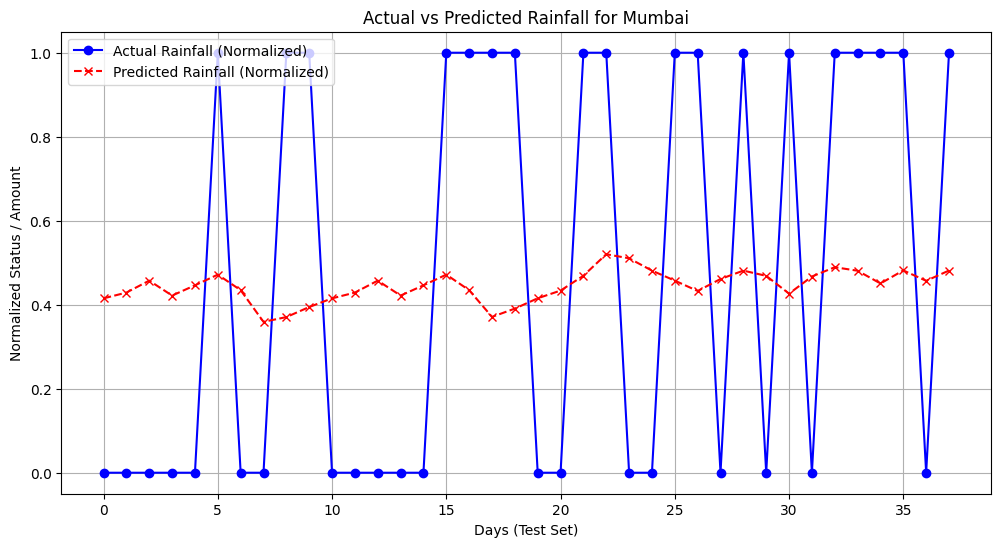

In [19]:
# Task 5: Plot Actual versus Predicted Rainfall & Demonstrate Unseen Predictions
plt.figure(figsize=(12, 6))
plt.plot(y_test, label='Actual Rainfall (Normalized)', color='blue', marker='o')
plt.plot(predictions, label='Predicted Rainfall (Normalized)', color='red', linestyle='dashed', marker='x')
plt.title(f'Actual vs Predicted Rainfall for {selected_location}')
plt.xlabel('Days (Test Set)')
plt.ylabel('Normalized Status / Amount')
plt.legend()
plt.grid(True)
plt.show()
